In [1]:
source('../../R/preamble.R')

small_titles = theme(axis.title = element_text(size=10))
small_text = theme(axis.text = element_text(size=8))

# Load cells records

In [2]:
library(vroom)

files = list.files('../../datasets/morphology/Cells/', full.names = T)
cells <- vroom(files)

#files2 = list.files('../../Exponential and stationary morphology (from stress scale gamma)/Cells/', full.names = T)
#cells <- vroom(files2)

Rows: 155149 Columns: 21


── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (4): file, condition, strain, fov
dbl (17): label, area, perimeter, solidity, orientation, axis_major_length, ...



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
cells[cells$strain == 'W', 'strain'] = 'WT'

# Clean the data

In [4]:
min_sharpness = 175
max_sharpness = 750
min_solidity = 0.8

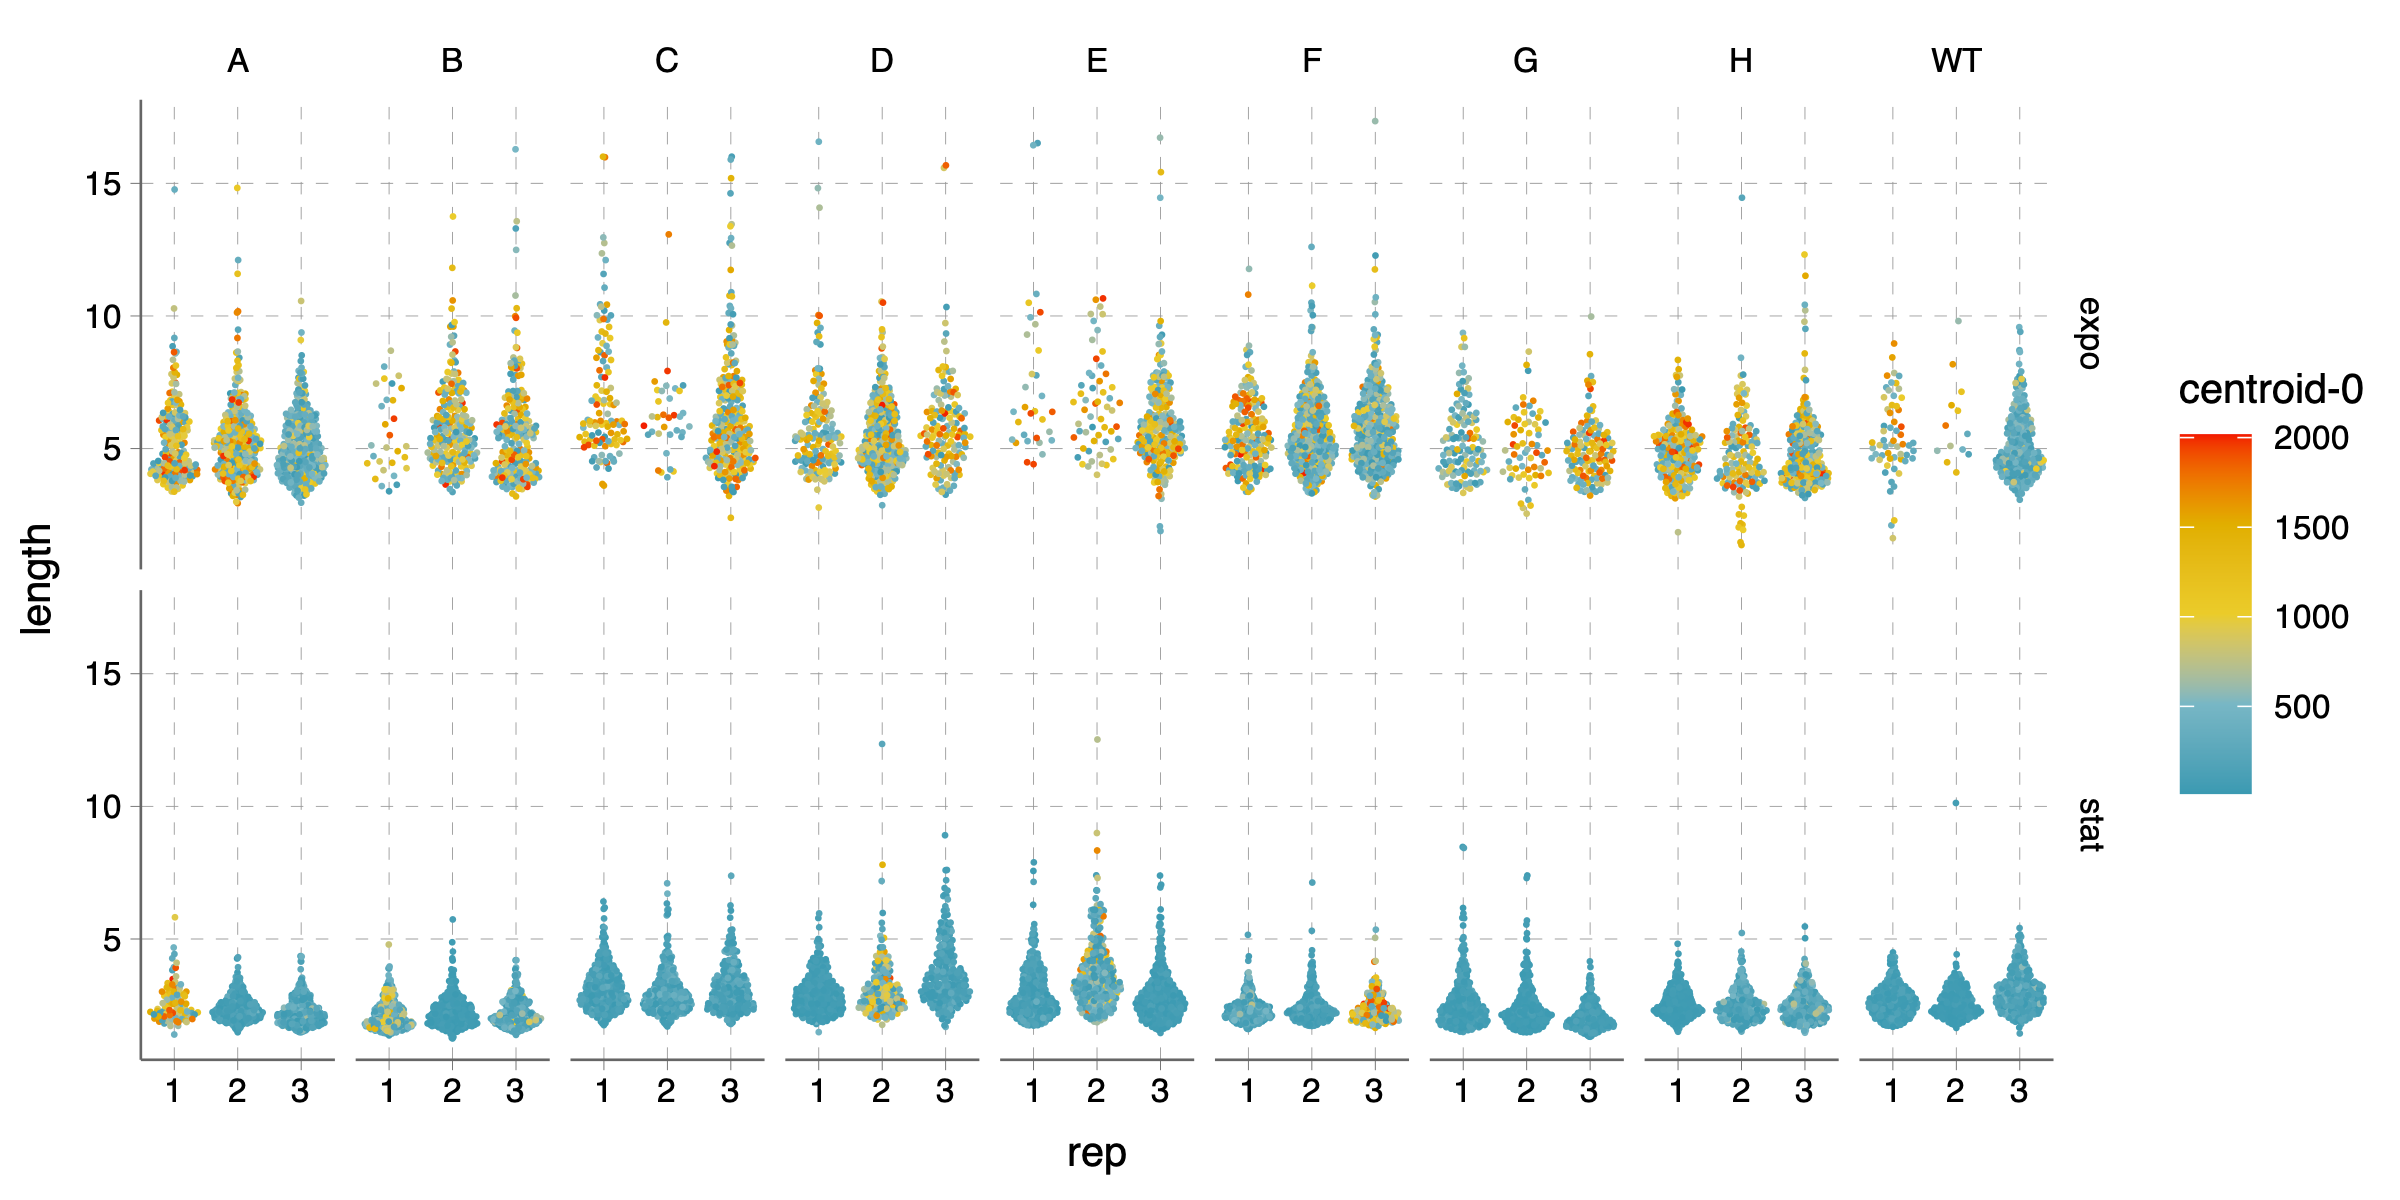

In [5]:
sub = cells %>%
    group_by(file) %>%
    filter(row_number() < 10)

size(4, 8)

sub %>% 
    filter(
        sharpness >= min_sharpness,
        sharpness <= max_sharpness,
        solidity >= min_solidity,
        connected <= 2, # allow clusters of 2 since they're mostly cells that just divided
        bg_mean < 12e3,
        bg_sd < 4e3
    ) %>% 

ggplot() + aes(rep, 
               length,
               #`centroid-0`, 
               col = `centroid-0`) + #nl +
    facet_grid(condition~strain) +
    #xlog() + 
    #ylog() +
    #geom_vline(xintercept = 0.8) +
    geom_quasirandom(size = 0.1)
    #geom_point(size = 0.1)

In [6]:
condition_labels = c('expo' = 'Exponential growth', 'stat' = 'Stationary phase')

d = cells %>%
    filter(
        sharpness >= min_sharpness,
        sharpness <= max_sharpness,
        solidity >= min_solidity,
        connected <= 2, # allow clusters of 2 since they're mostly cells that just divided
        bg_mean < 12e3,
        bg_sd < 4e3
    ) %>% 

    # Full names for conditions
    mutate(cond = condition_labels[condition])

# Average properties
**Solidity:** ratio of surface in the object / surface of the convex hulls

In [7]:
library(moments)

In [8]:
m = d %>%

    group_by(cond, condition, strain, rep) %>%
    summarise(
        w = mean(width), sd_w = sd(width), skew_w = skewness(width),
        l = mean(length), sd_l = sd(length), skew_l = skewness(length),
        s = mean(solidity),
        
        corr = cor(length, width, method = 'spearman')
        ) %>%
    ungroup()

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by cond, condition, strain, and rep.
ℹ Output is grouped by cond, condition, and strain.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(cond, condition, strain, rep))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


In [9]:
wt_values = m %>% filter(strain == 'WT') %>% 
    group_by(cond, condition) %>%
    summarise(
        l_mean = mean(l), l_min = min(l), l_max = max(l),
        w_mean = mean(w), w_min = min(w), w_max = max(w),
        
        l_cv = mean(sd_l / l), l_cv_min = min(sd_l / l), l_cv_max = max(sd_l / l),
        w_cv = mean(sd_w / w), w_cv_min = min(sd_w / w), w_cv_max = max(sd_w / w),
        
        l_skew = mean(skew_l), l_skew_min = min(skew_l), l_skew_max = max(skew_l),
        w_skew = mean(skew_w), w_skew_min = min(skew_w), w_skew_max = max(skew_w)
    )

size(4, 5)

contrast = pal[1]
cex = 2.25
ribbon_alpha = 0.075

plot_length_all =
m %>% 
ggplot() + aes() +
    ycont(0, 8.5) +
    facet_grid(~cond) + nl +

    geom_rect(data = wt_values, col = NA, alpha = ribbon_alpha, xmin = 0, xmax = 10, aes(ymin = l_min, ymax = l_max), fill = contrast) +
    geom_hline(data = wt_values, aes(yintercept = l_mean), col = contrast, lty = 2, lwd = 0.2) +

    theme(strip.text = eb) +

    geom_beeswarm(
        aes(x = fct_reorder(strain, strain != 'WT'), y = l, fill = strain != 'WT'),
        pch = 21, col = b, size = 2, stroke = 0.3, cex = cex
    ) +
    scale_fill_manual(values = c(contrast, w)) +

    labs(y = 'Mean length (μm)') + no_x_title()

plot_width_all =
m %>% 
ggplot() + aes() +
    ycont(0, 1.8) +
    facet_grid(~cond) + nl +

    geom_rect(data = wt_values, col = NA, alpha = ribbon_alpha, xmin = 0, xmax = 10, aes(ymin = w_min, ymax = w_max), fill = contrast) +
    geom_hline(data = wt_values, aes(yintercept = w_mean), col = contrast, lty = 2, lwd = 0.2) +

    geom_beeswarm(
        aes(x = fct_reorder(strain, strain != 'WT'), y = w, fill = strain != 'WT'),
        pch = 21, col = b, size = 2, stroke = 0.3, cex = cex
    ) +
    scale_fill_manual(values = c(contrast, w)) +

    labs(y = 'Mean width (μm)') + no_x_title()

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by cond and condition.
ℹ Output is grouped by cond.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(cond, condition))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


## Only pure lineages

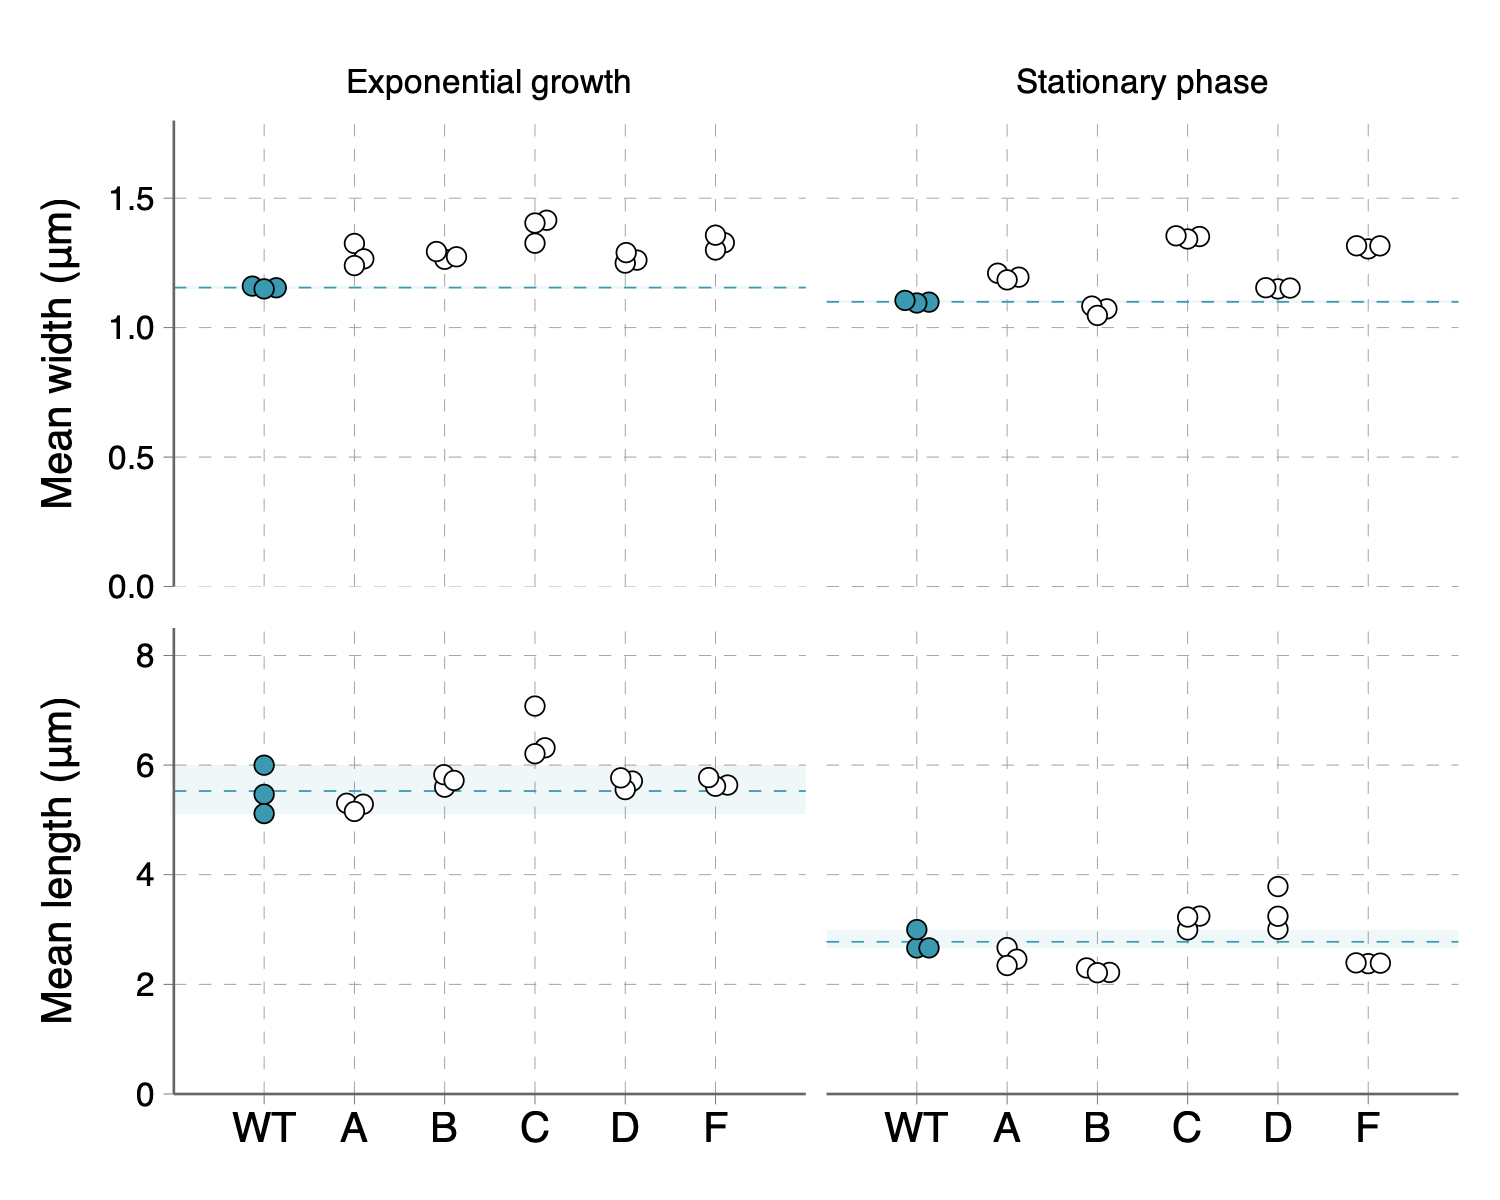

In [10]:
size(4, 5)

pure = c('WT', 'A','B','C','D','F')

contrast = pal[1]
cex = 2.25
ribbon_alpha = 0.075

plot_length =
m %>% filter(strain %in% pure) %>%  
ggplot() + aes() +
    ycont(0, 8.5) +
    facet_grid(~cond) + nl +

    geom_rect(data = wt_values, col = NA, alpha = ribbon_alpha, xmin = 0, xmax = 7, aes(ymin = l_min, ymax = l_max), fill = contrast) +
    geom_hline(data = wt_values, aes(yintercept = l_mean), col = contrast, lty = 2, lwd = 0.2) +

    theme(strip.text = eb) +

    geom_beeswarm(
        aes(x = fct_reorder(strain, strain != 'WT'), y = l, fill = strain != 'WT'),
        pch = 21, col = b, size = 2, stroke = 0.3, cex = cex
    ) +
    scale_fill_manual(values = c(contrast, w)) +

    labs(y = 'Mean length (μm)') + no_x_title()

plot_width =
m %>%  filter(strain %in% pure) %>% 
ggplot() + aes() +
    ycont(0, 1.8) +
    facet_grid(~cond) + nl +

    geom_rect(data = wt_values, col = NA, alpha = ribbon_alpha, xmin = 0, xmax = 7, aes(ymin = w_min, ymax = w_max), fill = contrast) +
    geom_hline(data = wt_values, aes(yintercept = w_mean), col = contrast, lty = 2, lwd = 0.2) +

    geom_beeswarm(
        aes(x = fct_reorder(strain, strain != 'WT'), y = w, fill = strain != 'WT'),
        pch = 21, col = b, size = 2, stroke = 0.3, cex = cex
    ) +
    scale_fill_manual(values = c(contrast, w)) +

    labs(y = 'Mean width (μm)') + no_x_title()

(plot_width / plot_length) + plot_layout(axes = 'collect')

#psave('Plots/morphology_pure')

In [11]:
eb_size = 0.02
lwd = 0.3
wt_color = pal[1]

size(2.5, 2.5)

m_sum =
m %>%
    select(condition, strain, rep, w, l) %>%
    group_by(condition, strain) %>%
    summarise(
        # w_mean = median(w), w_min = min(w), w_max = max(w),
        # l_mean = median(l), l_min = min(l), l_max = max(l), # basically the same but harder to read
        w_mean = mean(w), w_min = mean(w) - sd(w), w_max = mean(w) + sd(w),
        l_mean = mean(l), l_min = mean(l) - sd(l), l_max = mean(l) + sd(l)
        ) %>% 
    ungroup() %>% 

    pivot_wider(names_from = condition, values_from = c(w_mean, w_min, w_max, l_mean, l_min, l_max))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by condition and strain.
ℹ Output is grouped by condition.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(condition, strain))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


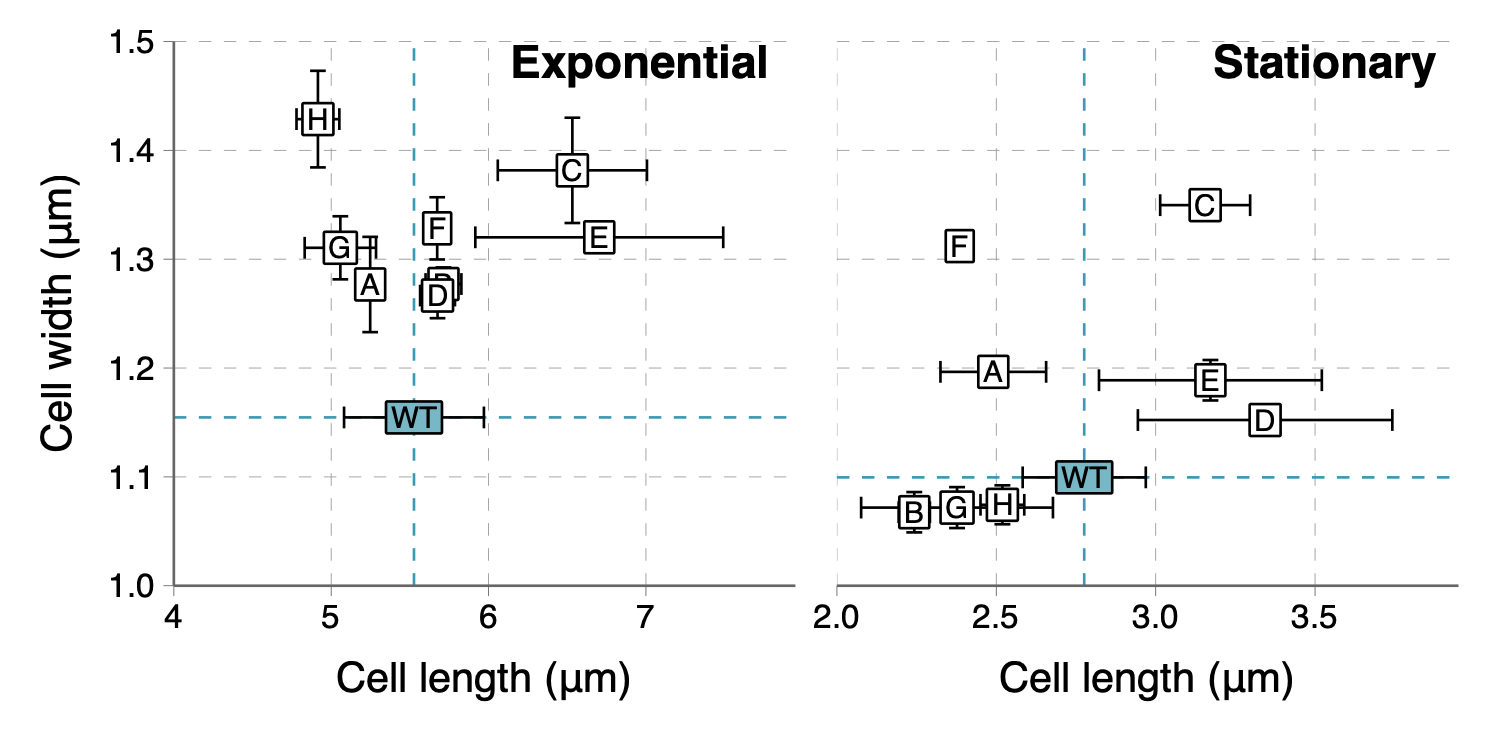

In [12]:
eb_size_w = 0.02
eb_size_l = 0.10
lwd = 0.3
wt_fill = pal[2]
r = 0.3

options(warn = -1)

morpho_expo_plot =
m_sum %>% #filter(strain %in% pure) %>% 

ggplot() + aes(
        l_mean_expo, xmin = l_min_expo, xmax = l_max_expo,
        w_mean_expo, ymin = w_min_expo, ymax = w_max_expo,
        fill = strain != 'WT',
        label = strain
    ) +

    xcont(4, 7.95) + ycont(1, 1.5) +

    # WT
    scale_fill_manual(values = c(wt_fill, w)) + nl +
    geom_hline(yintercept = filter(m_sum, strain == 'WT')$w_mean_expo, lwd = lwd, col = wt_color, lty = 2) +
    geom_vline(xintercept = filter(m_sum, strain == 'WT')$l_mean_expo, lwd = lwd, col = wt_color, lty = 2) +

    geom_errorbar(width = eb_size_l, lwd = lwd) + geom_errorbarh(height = eb_size_w, lwd = lwd) +
    geom_label(size = 2.5, label.size = lwd, label.padding = unit(1.2,'pt'), label.r = unit(r,'pt')) +

    #theme(plot.title = element_text(face = 'plain', hjust = 0.5, size = 11)) +
    annotate(
        geom = 'text', x = 7.95, y = 1.5, label = 'Exponential',
        vjust = 1.12, hjust = 1.1, fontface = 'bold'
    ) +
    labs(x = 'Cell length (μm)', y = 'Cell width (μm)')

morpho_stat_plot =
m_sum %>% #filter(strain %in% pure) %>% 

ggplot() + aes(
        l_mean_stat, xmin = l_min_stat, xmax = l_max_stat,
        w_mean_stat, ymin = w_min_stat, ymax = w_max_stat,
        fill = strain != 'WT',
        label = strain
    ) +

    xcont(2, 3.95) + 
    ycont(1, 1.5) +

    # WT
    scale_fill_manual(values = c(wt_fill, w)) + nl +
    geom_hline(yintercept = filter(m_sum, strain == 'WT')$w_mean_stat, lwd = lwd, col = wt_color, lty = 2) +
    geom_vline(xintercept = filter(m_sum, strain == 'WT')$l_mean_stat, lwd = lwd, col = wt_color, lty = 2) +

    geom_errorbar(width = eb_size_l*0.5, lwd = lwd) + geom_errorbarh(height = eb_size_w, lwd = lwd) +
    geom_label(size = 2.5, label.size = lwd, label.padding = unit(1.2,'pt'), label.r = unit(r,'pt')) +

    annotate(
        geom = 'text', x = 3.95, y = 1.5, label = 'Stationary',
        vjust = 1.12, hjust = 1.1, fontface = 'bold'
    ) +
    labs(x = 'Cell length (μm)', y = 'Cell width (μm)')

size(2.5, 5)
(morpho_expo_plot | morpho_stat_plot) + plot_layout(axes = 'collect_y')
psave('Plots/morpho_expo_stat')

In [13]:
size(2.5,2.5)

eb_size=0.02
title_size=10
title_face='bold'
title_color='grey20'
lwd = 0.25
padding = unit(1.2,'pt')
r = unit(2,'pt')

width_plot =
m_sum %>% #filter(strain %in% pure) %>% 

ggplot() + aes(
        w_mean_stat, xmin = w_min_stat, xmax = w_max_stat,
        w_mean_expo, ymin = w_min_expo, ymax = w_max_expo,
        fill = strain != 'WT',
        label = strain
    ) +

    #xcont(1.1, 1.55) + 
    ycont(1, NA) +

    # WT
    scale_fill_manual(values = c(wt_fill, w)) + nl +
    geom_vline(xintercept = filter(m_sum, strain == 'WT')$w_mean_stat, lwd = 0.3, col = wt_color, lty = 2) +
    geom_hline(yintercept = filter(m_sum, strain == 'WT')$w_mean_expo, lwd = 0.3, col = wt_color, lty = 2) +

    geom_errorbar(width = eb_size, lwd = lwd) + geom_errorbarh(height = eb_size, lwd = lwd) +
    #geom_point(pch = 21, col = b, size = 1.6, stroke = lwd * 1.5) +
    geom_label(size = 2.5, label.size = lwd, label.padding = padding, label.r = r) +

    #theme(plot.title = element_text(face = 'bold', hjust = 0.5, size = 11)) +
    small_titles + small_text +
    #add_text(1.54, 1.46, 'Cell width (μm)', size = title_size, hjust=1, vjust=1, fontface=title_face, col=title_color) +

    theme(plot.title = element_text(hjust=0.5, size=title_size, color=title_color, face=title_face, margin=margin(0,0,1,0))) +
    labs(y = 'Exponential width (μm)', x = 'Stationary width (μm)')

saveRDS(width_plot, 'Plots/GG/width_expo_vs_stat.rds')

In [14]:
size(2.5, 2.5)

eb_size = 0.1

length_plot =
m_sum %>% #filter(strain %in% pure) %>% 

ggplot() + aes(
        l_mean_stat, xmin = l_min_stat, xmax = l_max_stat,
        l_mean_expo, ymin = l_min_expo, ymax = l_max_expo,
        fill = strain != 'WT',
        label = strain
    ) +

    #xcont(1.1, 1.5) + 
    #ycont(1.9, 3.99, breaks = seq(2, 4, 0.4)) +

    # WT
    scale_fill_manual(values = c(wt_fill, w)) + nl +
    geom_vline(xintercept = filter(m_sum, strain == 'WT')$l_mean_stat, lwd = 0.3, col = wt_color, lty = 2) +
    geom_hline(yintercept = filter(m_sum, strain == 'WT')$l_mean_expo, lwd = 0.3, col = wt_color, lty = 2) +

    geom_errorbar(width = eb_size, lwd = lwd) + geom_errorbarh(height = eb_size, lwd = lwd) +
    #geom_point(pch = 21, col = b, size = 1.6, stroke = lwd * 1.5) +
    geom_label(size = 2.5, label.size = lwd, label.padding = padding, label.r = r) +

    theme(plot.title = element_text(face = 'bold', hjust = 0.5, size = 11)) +
    small_titles + small_text +
    #add_text(7.51, 4.09, 'Cell length (μm)', size = title_size, hjust=1, vjust=1, fontface='bold', col=title_color) +

    theme(plot.title = element_text(hjust=0.5, size=title_size, color=title_color, face=title_face, margin=margin(0,0,1,0))) +
    labs(y = 'Exponential length (μm)', x = 'Stationary length (μm)')

saveRDS(length_plot, 'Plots/GG/length_expo_vs_stat.rds')      

### Stationary shape vs mutation accumulation

Joining with `by = join_by(strain)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by strain and n_mut.
ℹ Output is grouped by strain.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(strain, n_mut))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


[1] 0.2728132


[1] 0.187879


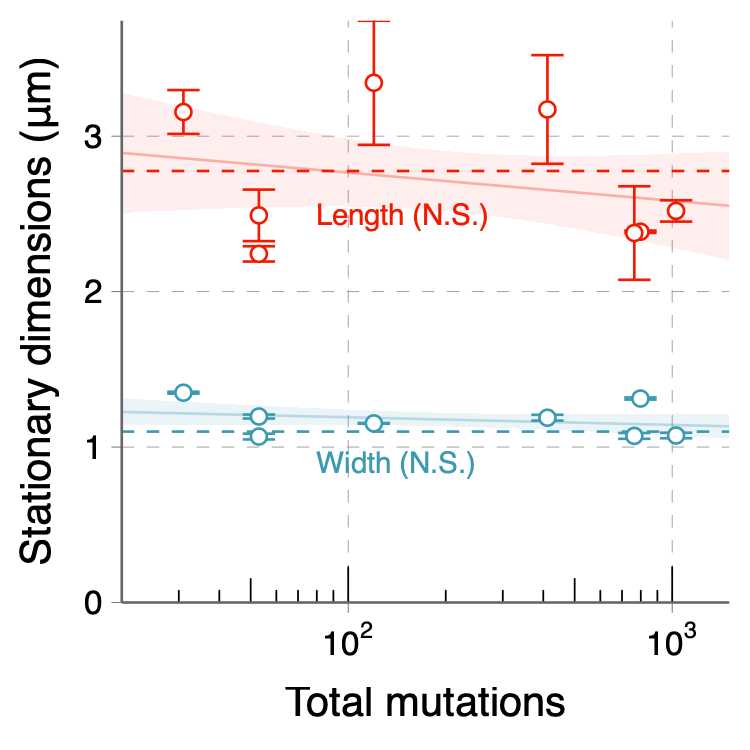

In [15]:
d = read.tsv('../../datasets/genomics/04_gene_attribution/results/d_labeled.tsv')

strain_to_n_mut = d %>%
    filter(gen == 24, freq > 0.95) %>% 
    #filter(cat=='synonymous') %>%
    group_by(pop) %>%
    summarise(n_mut = n()) %>% 
    rename(strain=pop) %>% 
    add_row(strain='WT', n_mut=0)

lwd = 0.3
xmin = 2e1
xmax = 1.5e3
contrast_w = pal[1]
contrast_l = pal[5]
sz = 1.5
text_size = 2.5

df =
m %>%
    filter(condition=='stat') %>% 

    mutate(l_wt = mean(l[strain=='WT'])) %>% 
    filter(strain!='WT') %>%

    left_join(strain_to_n_mut) %>% 
    ungroup() %>% 
    mutate(
        log_n_mut = log10(n_mut),
        rl = l / l_wt
    )

summary_df =
    df %>% 
    group_by(strain, n_mut) %>%
    summarise(
        ml = mean(l), sl = sd(l),
        mw = mean(w), sw = sd(w)
    ) %>%
    ungroup()

# Linear reg
model_l = lm(l ~ log_n_mut, data = df)

# Get predictions and confidence intervals
pred_df_l = data.frame(log_n_mut = seq(log10(xmin), log10(xmax), length.out = 100))
pred_df_l = cbind(pred_df_l, predict(model_l, newdata = pred_df_l, interval = "confidence"))

# Get p-value
p_value_l = summary(model_l)$coefficients["log_n_mut", "Pr(>|t|)"]
print(p_value_l)

# Linear reg
model_w = lm(w ~ log_n_mut, data = df)

# Get predictions and confidence intervals
pred_df_w = data.frame(log_n_mut = seq(log10(xmin), log10(xmax), length.out = 100))
pred_df_w = cbind(pred_df_w, predict(model_w, newdata = pred_df_w, interval = "confidence"))

# Get p-value
p_value_w = summary(model_w)$coefficients["log_n_mut", "Pr(>|t|)"]
print(p_value_w)

size(2.5, 2.5)

stat_morphology_vs_mutations_plot =
ggplot() + 

    ycont(0, NA) +
    xlog(xmin, xmax, breaks=c(1e2,1e3)) + logticks('b') +


    ### Length ###

    # Regression
    geom_ribbon(data = pred_df_l, aes(x=10^log_n_mut, min = lwr, max = upr), fill = contrast_l, alpha = 0.07) +
    geom_line(
        data = pred_df_l, aes(x=10^log_n_mut, y = fit), 
        color = contrast_l, lwd = lwd, alpha = 0.3
    ) +
    add_text(
        0.8e2, 2.5, 'Length (N.S.)',
        col = contrast_l, fontface = 'plain', hjust = 0, size = text_size
    ) +

    # Data
    geom_hline(
        yintercept = mean(m[(m$strain == 'WT') & (m$condition == 'stat'),]$l),
        lwd = lwd, lty = 2, col = contrast_l
    ) +
    geom_errorbar(
        data = summary_df,
        aes(n_mut, ml, min=ml-sl, max=ml+sl),
        lwd = lwd, width = 0.1, col = contrast_l
    ) +
    geom_point(
        data = summary_df,
        aes(n_mut, ml),
        pch = 21, size = sz, fill = w, stroke = lwd*1.5, col = contrast_l
    ) +

    ### Width ###

    # Regression
    geom_ribbon(data = pred_df_w, aes(x=10^log_n_mut, min = lwr, max = upr), fill = contrast_w, alpha = 0.1) +
    geom_line(
        data = pred_df_w, aes(x=10^log_n_mut, y = fit), 
        color = contrast_w, lwd = lwd, col = contrast_w, alpha = 0.3
    ) +
    add_text(
        0.8e2, 0.9, 'Width (N.S.)',
        col = contrast_w, size = text_size, fontface = 'plain', hjust = 0
    ) +

    # Data
    geom_hline(
        yintercept = mean(m[(m$strain == 'WT') & (m$condition == 'stat'),]$w),
        lwd = lwd, lty = 2, col = contrast_w
    ) +
    geom_errorbar(
        data = summary_df,
        aes(n_mut, mw, min=mw-sw, max=mw+sw),
        lwd = lwd, width = 0.1, col = contrast_w
    ) +
    geom_point(
        data = summary_df,
        aes(n_mut, mw),
        pch = 21, size = sz, fill = w, stroke = lwd*1.5, col = contrast_w
    ) +

    small_titles + small_text +
    labs(x = 'Total mutations', y = 'Stationary dimensions (μm)')

stat_morphology_vs_mutations_plot
psave('Plots/stat_morphology_vs_mutations')